# VAR
Carlos Santiago Nava Pulido

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from IPython.core.display import display_webp

## FUNCIONES DE SIMULACÓN MULTIACTIVO Y VALUADOR DE PORTAFOLIO

In [76]:
def mercado_multiactivo(S0,mu,sigma,corr,T,num_steps,num_simulations,seed=42):
    np.random.seed(seed)

    S0 = np.asarray(S0)
    mu = np.asarray(mu)
    sigma = np.asarray(sigma)
    n_assets = len(S0)
    dt = T / num_steps

    # Cholesky
    L = np.linalg.cholesky(corr)
    # ERRORES NORMALES
    Z = np.random.normal(0,1,size=(n_assets, num_steps, num_simulations))
    # Correlacionar
    Z_corr = np.tensordot(L, Z, axes=(1, 0))

    # GBM
    drift = (mu[:, None, None]- 0.5 * sigma[:, None, None]**2) * dt
    diffusion = (sigma[:, None, None]* np.sqrt(dt)* Z_corr)
    log_returns = drift + diffusion

    # t=0
    log_returns = np.concatenate([np.zeros((n_assets, 1, num_simulations)), log_returns ],axis=1)
    prices = (  S0[:, None, None] * np.exp(np.cumsum(log_returns, axis=1)))

    return prices


In [77]:
def valorar_portafolios(precios, W, S0, Vo=100_000):

    S0 = np.asarray(S0)
    W = np.array(W)
    relativos = precios[:,-1,:] / S0[:,None]
    valores = Vo * np.tensordot(W,relativos,axes=(0,0))
    return valores.squeeze()

PESOS DEL PORTAFOLIO

In [78]:
portafolio = {
    'p1': [1,0,0],
    'p2': [.33,.33,.34],
    'p3': [.2,.2,.6]
}

TICKERS...

In [79]:
tickers = ['AAPL', 'MSFT', 'NVDA']
precios = yf.download(tickers, period='1y', interval='1d', progress=False)['Close'].dropna()
rend = (np.log(precios)).diff().dropna()

In [80]:
S0 = precios.iloc[-1]
r = np.mean(rend, axis=0) * 252
sigma = np.std(rend, axis=0) * np.sqrt(252)
display(S0, r, sigma)

Ticker
AAPL    355.630005
MSFT    521.130005
NVDA    173.729996
Name: 2026-11-11 00:00:00, dtype: float64

Ticker
AAPL    0.267540
MSFT    0.027770
NVDA   -0.107787
dtype: float64

Ticker
AAPL    0.249891
MSFT    0.336284
NVDA    0.385899
dtype: float64

SIMULACIÓN Y VALUACIÓN POR CADA CASO..

In [81]:
corr_rend = np.array(rend.corr())
precios = mercado_multiactivo(S0, r, sigma, corr_rend,1, num_simulations = 1000000, num_steps = 1)

### ALMACENAMIENTO DE PRECIOS SIMULADOS Y CALCULO PNL

In [82]:

PnL_corr= {
    'p1': [],
    'p2': [],
    'p3':[]
}
V0 = 100_000
for i in portafolio.keys():
    W = np.array(portafolio[i])
    PnL_corr[i] = valorar_portafolios(precios,W,S0,V0)-V0

### GRAFICA DE PnL

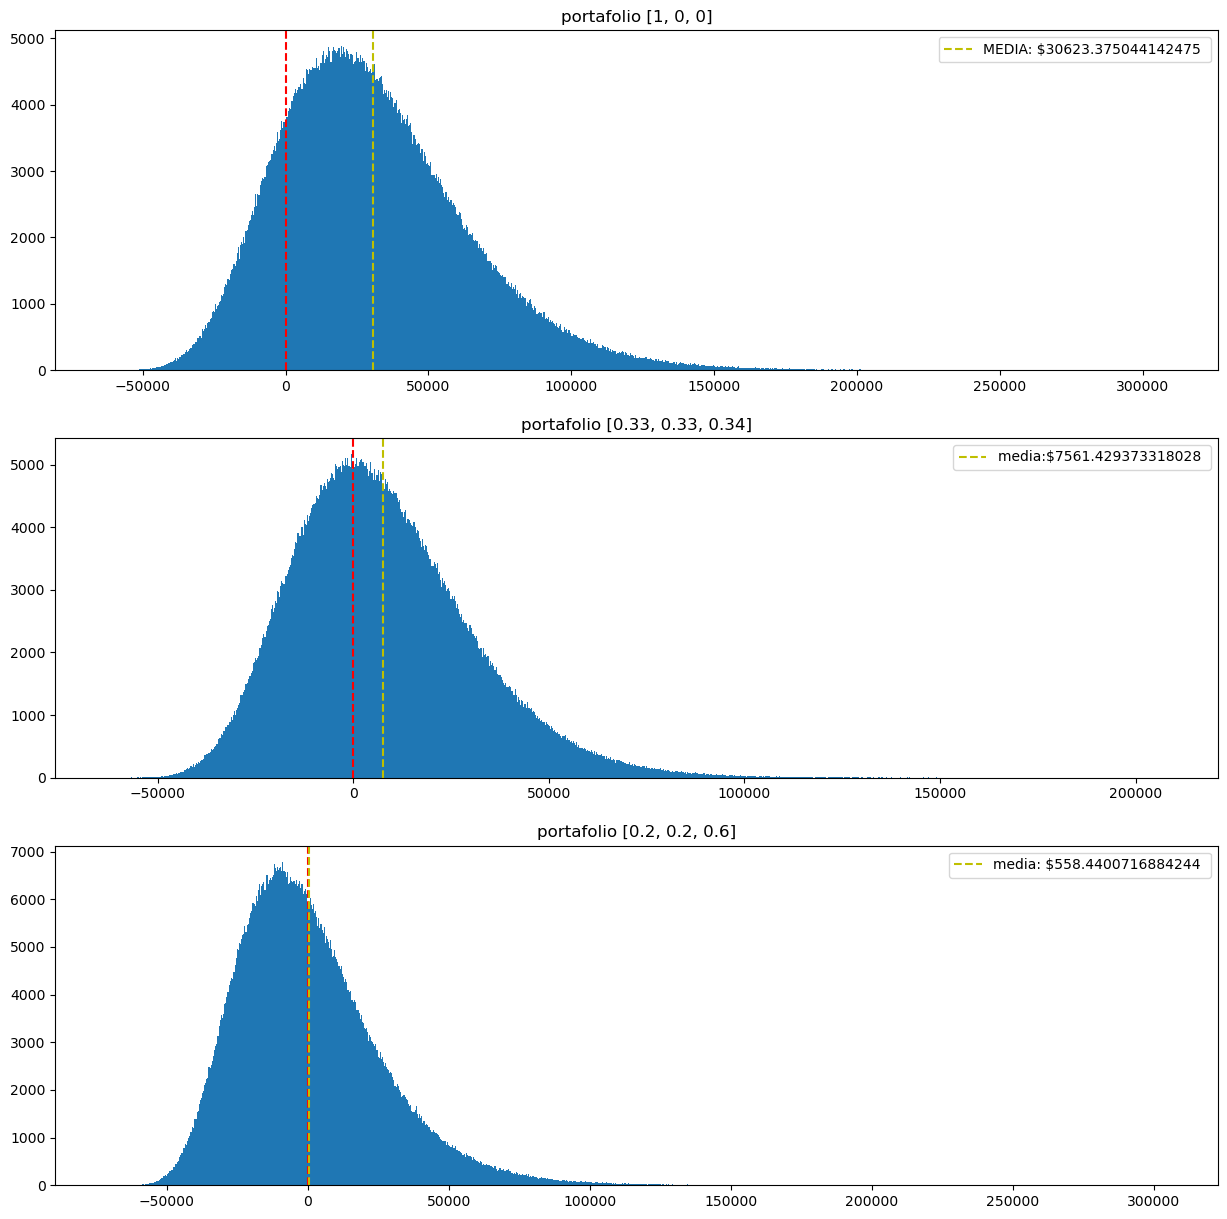

In [83]:


plt.figure(figsize=(15,15))
plt.subplot(3,1,1)
plt.title(f'portafolio {portafolio['p1']}')

plt.hist(PnL_corr['p1'], bins=1000)
plt.axvline(x=0, color='r', linestyle='dashed')
plt.axvline(x = np.mean(PnL_corr['p1']), color='y', linestyle='dashed', label = f'MEDIA: ${np.mean(PnL_corr['p1'])} ')
plt.legend()
plt.subplot(3,1,2)
plt.title(f'portafolio {portafolio['p2']}')
plt.axvline(x=0, color='r', linestyle='dashed')
plt.axvline(x = np.mean(PnL_corr['p2']), color='y', linestyle='dashed', label = f'media:${np.mean(PnL_corr['p2'])} ')
plt.legend()
plt.hist(PnL_corr['p2'], bins=1000)
plt.subplot(3,1,3)
plt.title(f'portafolio {portafolio['p3']}')
plt.axvline(x=0, color='r', linestyle='dashed')
plt.axvline(x = np.mean(PnL_corr['p3']), color='y', linestyle='dashed', label = f'media: ${np.mean(PnL_corr['p3'])} ')
plt.legend()
plt.hist(PnL_corr['p3'], bins=1000)
plt.show()

## VAR Y CVAR

FUNCIÓN DE GRAFICACIÓN VAR

In [86]:


def plot_VaR(VaR, cVar, serie, nombre):
    plt.figure(figsize=(10,4))
    plt.title(nombre)

    counts, bins, patches = plt.hist(serie, bins=1000, density=True, alpha=0.7, color='b', label = 'ALPHA: .05')

    for patch, left_edge in zip(patches, bins[:-1]):
        if left_edge <= VaR:
            patch.set_facecolor('r')

    plt.axvline(x=VaR, color='r', linestyle='dashed', label=f'VaR: ${VaR:.2f}')
    plt.axvline(x=cVar, color='g', linestyle='dashed', label=f'CVaR: ${cVar:.2f}')
    plt.axvline(x=np.mean(serie), color='k', linestyle='dashed', label=f'Media: ${np.mean(serie):.2f}')
    plt.legend()
    plt.show()

## CALCULO Y FILTRO
VaR = $$\text{percentile}(PnL), .95)$$
cVaR = $$E[R_p|R_p\le P_{.05}]$$

p1 -> VaR (95%): -16,070.2898 | CVaR (95%): -24,104.2184


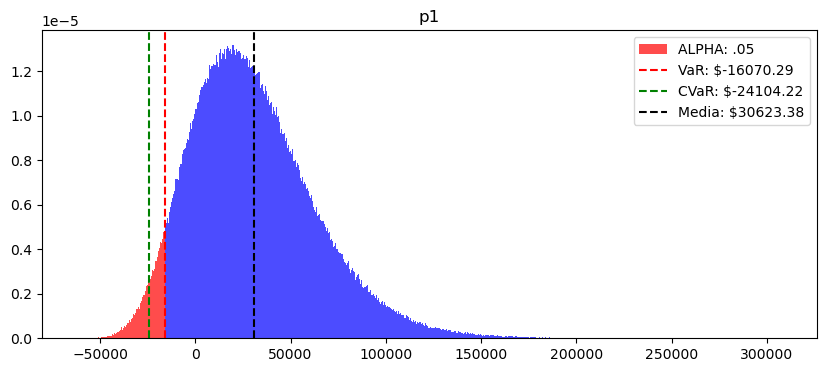

CONCLUSIÓN: Dado el portafolio [1, 0, 0] con un intervalo de 95%, se puede decir que la pérdida máxima esperada sería -16070.29 y el promedio en perdidas dado el mismo intervalo sería -24104.22 esto para un horizonte anual.
p2 -> VaR (95%): -25,296.6527 | CVaR (95%): -31,251.7891


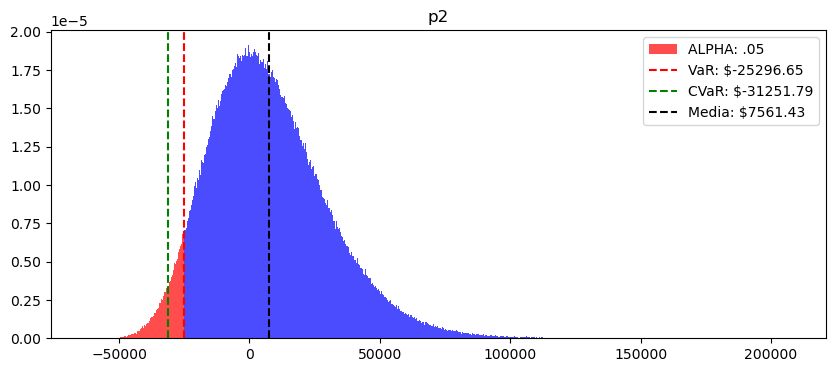

CONCLUSIÓN: Dado el portafolio [0.33, 0.33, 0.34] con un intervalo de 95%, se puede decir que la pérdida máxima esperada sería -25296.65 y el promedio en perdidas dado el mismo intervalo sería -31251.79 esto para un horizonte anual.
p3 -> VaR (95%): -34,262.3071 | CVaR (95%): -39,977.7960


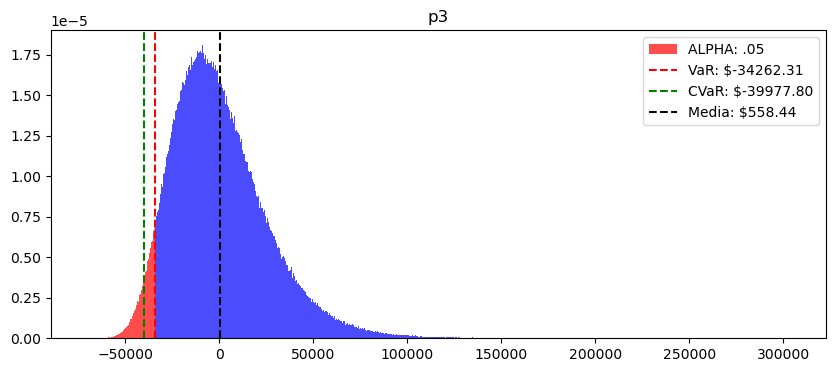

CONCLUSIÓN: Dado el portafolio [0.2, 0.2, 0.6] con un intervalo de 95%, se puede decir que la pérdida máxima esperada sería -34262.31 y el promedio en perdidas dado el mismo intervalo sería -39977.80 esto para un horizonte anual.


In [92]:
for i in PnL_corr.keys():
    serie = np.asarray(PnL_corr[i])
    var_95 = np.percentile(serie, 5)
    cvar_95 = np.mean(serie[serie <= var_95])
    print(f"{i} -> VaR (95%): {var_95:,.4f} | CVaR (95%): {cvar_95:,.4f}")
    plot_VaR(var_95, cvar_95, serie, i)
    print(f"CONCLUSIÓN: Dado el portafolio {portafolio[i]} con un intervalo de 95%, se puede decir que la pérdida máxima esperada sería {var_95:.2f} y el promedio en perdidas dado el mismo intervalo sería {cvar_95:.2f} esto para un horizonte anual.")


CONCLUSIÓN:


El calculo de Var y cVaR resulta ser conveniente considerando otros métodos como son las paramétricas, sobre todo por la posibilidad de simular la relación de los activos involucrados a diferencia de otros métodos que lo consideran.